In [6]:
%pip install numpy pandas matplotlib pillow scikit-learn tensorflow ipython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Classificação de cenas naturais (Intel Image Classification) com CNNs — TensorFlow/Keras

**Pergunta central:** quanto custa cada ponto de *accuracy* em parâmetros, tempo e dados? Comparamos, seguindo o fluxo da aula, um **baseline denso (MLP)**, uma **CNN treinada do zero** (com e sem regularização) e **redes pré-treinadas** (*feature extraction* vs *fine-tuning*), e analisamos *overfitting*, generalização e erros.

**Ligação à matéria (slides da aula)**

| Secção | Onde está na aula |
|---|---|
| Protocolo hold-out, redundância/fuga de dados | *ML fundamentals* — treino/validação/teste, "redundancy in your data" |
| Baseline MLP, softmax + `categorical/sparse_categorical_crossentropy` | *Multiclass classification* (Reuters) |
| CNN do zero (Conv2D + MaxPooling2D + Flatten + Dense) | *CNNs* — convnet dogs vs cats |
| Overfitting → *data augmentation*, *dropout*, L2, reduzir capacidade | *ML fundamentals* e *CNNs* |
| VGG16/ResNet/MobileNet/EfficientNet: *feature extraction* e *fine-tuning* | *CNNs* — "Using a pretrained network" |
| Grad-CAM na análise de erros | *CNNs* — material opcional |

**Como usar:** configurar a célula seguinte, correr tudo de cima para baixo. Cada experiência grava um `.json` em `RESULTS/runs_<perfil>/`; se a sessão cair, voltar a correr retoma sem repetir. As secções de análise lêem esses ficheiros.

In [7]:
# ============================ CONFIGURAÇÃO ============================
DATA_ROOT   = r"C:\Users\ramos\OneDrive\Ambiente de Trabalho\seg_image"   # pasta com seg_train, seg_test (e seg_pred, não usada)
RESULTS_DIR = None        # None = pasta "results_keras" junto do notebook (no Colab: dl_project/results_keras no Drive)
PROFILE     = "auto"      # "auto" | "gpu" | "cpu" | "rapido" | "smoke"   (auto: gpu se houver GPU, senão rapido; smoke = só testa o pipeline)
IMG_SIZE    = 150         # resolução de entrada (original: 150x150)
OPTIMIZER   = "adam"      # a aula usa rmsprop; adam costuma convergir mais depressa
RUN_GROUPS  = ["baselines", "scratch", "regularization", "pretrained", "learning_curve", "augmentation"]
N_SEEDS           = None  # None = valor do perfil; mais seeds = barras de erro mais fiáveis, mas mais tempo
PRETRAINED_MODELS = None  # None = valor do perfil, ex.: ["MobileNetV2", "ResNet50"]
WEIGHTS     = "imagenet"  # pesos pré-treinados (precisa de internet); None = aleatórios (só para testes)
FORCE       = False       # True = repete experiências já guardadas

In [8]:
# ============================ SETUP ============================
import os, sys, json, time, io, hashlib, zipfile, datetime, random
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import tensorflow as tf
import keras
from keras import layers, regularizers
from IPython.display import display

IN_COLAB = "google.colab" in sys.modules
GPUS = tf.config.list_physical_devices("GPU")
if PROFILE == "auto":
    PROFILE = "smoke" if os.environ.get("SMOKE") == "1" else ("gpu" if GPUS else "rapido")
PROFILES = {
    "gpu":   dict(n_seeds=2, models=["MobileNetV2", "ResNet50", "EfficientNetB0", "VGG16"], e_scratch=30, e_head=8, e_ft=8, fracs=[0.1, 0.25, 0.5, 1.0], patience=6),
    "cpu":   dict(n_seeds=1, models=["MobileNetV2"], e_scratch=12, e_head=5, e_ft=5, fracs=[0.1, 0.25, 1.0], patience=4),
    "rapido": dict(n_seeds=1, models=["MobileNetV2"], e_scratch=6, e_head=3, e_ft=3, fracs=[0.25, 1.0], patience=3, img_size=96),   # CPU: resultados reais, mas reduzidos
    "smoke": dict(n_seeds=1, models=["MobileNetV2"], e_scratch=2, e_head=1, e_ft=1, fracs=[0.5, 1.0], patience=2),
}
P = dict(PROFILES[PROFILE])
if N_SEEDS is not None: P["n_seeds"] = N_SEEDS
if PRETRAINED_MODELS is not None: P["models"] = PRETRAINED_MODELS
IMG_SIZE = P.get("img_size", IMG_SIZE)      # o perfil "rapido" usa imagens mais pequenas (96x96) para treinar bem mais depressa
SMOKE = PROFILE == "smoke"
if SMOKE and WEIGHTS == "imagenet" and os.environ.get("SMOKE_WEIGHTS") != "1": WEIGHTS = None

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive"); BASE = Path("/content/drive/MyDrive/dl_project")
else:
    BASE = Path(".")
RESULTS = Path(RESULTS_DIR or os.environ.get("RESULTS_DIR") or (BASE / "results_keras"))
RUNS, MODELS_DIR, FIG = RESULTS / f"runs_{PROFILE}", RESULTS / f"models_{PROFILE}", RESULTS / "figures"
for d in (RUNS, MODELS_DIR, FIG): d.mkdir(parents=True, exist_ok=True)

CLASSES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
N_CLS = len(CLASSES)
SPLIT_SEED = 42   # FIXA: a mesma validação e os mesmos subconjuntos em todas as experiências
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | GPU: {[g.name for g in GPUS] or 'nenhuma'}")
print(f"perfil = {PROFILE} | resolução = {IMG_SIZE} | {P}")
print(f"resultados em: {RESULTS.resolve()}")
if not GPUS and PROFILE != "smoke":
    print(f"AVISO: sem GPU -> perfil '{PROFILE}' (reduzido). No Windows nativo o TensorFlow já não usa GPU; para o perfil completo usa o Google Colab (GPU) ou WSL2.")

TensorFlow 2.21.0 | Keras 3.15.1 | GPU: nenhuma
perfil = rapido | resolução = 96 | {'n_seeds': 1, 'models': ['MobileNetV2'], 'e_scratch': 6, 'e_head': 3, 'e_ft': 3, 'fracs': [0.25, 1.0], 'patience': 3, 'img_size': 96}
resultados em: C:\Users\ramos\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\F2E70E96E59E8699683B741B2CCF663BB5404C3F\transfers\2026-46\results_keras
AVISO: sem GPU -> perfil 'rapido' (reduzido). No Windows nativo o TensorFlow já não usa GPU; para o perfil completo usa o Google Colab (GPU) ou WSL2.


## 1 · Definição do problema e protocolo de avaliação

* **Tarefa:** classificação de uma imagem de cena natural (150×150 RGB) numa de 6 classes: `buildings`, `forest`, `glacier`, `mountain`, `sea`, `street` (classificação multiclasse com uma só etiqueta → saída *softmax* de 6 unidades).
* **Métrica principal:** *accuracy* (as classes estão equilibradas, como nos slides: "balanced … accuracy is an appropriate measure"), com F1 macro e matriz de confusão para a análise de erros. Eficiência: nº de parâmetros, GFLOPs (estimativa), tamanho em disco, latência de inferência e tempo de treino.
* **Protocolo (aula *ML fundamentals*):** *hold-out* — `seg_train` dividido em treino (85 %) e validação (15 %, estratificada, **semente fixa**); `seg_test` só é usado **no fim de cada experiência**, nunca para escolher hiperparâmetros nem modelos. Escolhemos o "melhor modelo" **pela validação**.
* **Porquê hold-out e não K-fold:** com ~14 mil imagens a validação (~2 100) é suficientemente grande; K-fold só seria necessário com poucos dados. A variância é estimada repetindo cada experiência com várias *seeds*.
* **Redundância:** verificamos duplicados exatos (hash) dentro do treino e entre treino e teste, para garantir conjuntos disjuntos.
* **Ordem do trabalho (slide "Summary" da aula):** baseline trivial → primeiro modelo com poder estatístico → modelo que **faz overfitting** → regularizar → usar modelo pré-treinado.

## 2 · Dados
Procura `seg_train`/`seg_test` em `DATA_ROOT` (e, se não encontrar, no Drive, em `/kaggle/input` ou em `./data`; também descompacta `seg_train.zip`/`seg_test.zip`). As imagens são carregadas **uma vez** para memória (uint8, 150×150).

treino: C:\Users\ramos\OneDrive\Ambiente de Trabalho\seg_image\seg_train 
teste:  C:\Users\ramos\OneDrive\Ambiente de Trabalho\seg_image\seg_test
carregadas 14034 imagens de treino e 3000 de teste em 20s | 947 MB
duplicados exatos no treino: 15 | imagens do treino também presentes no teste: 3
-> treino sem duplicados/fuga: 14016 imagens
treino: 11913 | validação: 2103 | teste: 3000
imagens por classe (treino): {'buildings': 2190, 'forest': 2269, 'glacier': 2404, 'mountain': 2505, 'sea': 2272, 'street': 2376}
baseline trivial (classe mais frequente) no teste: 0.184 | acaso: 0.167


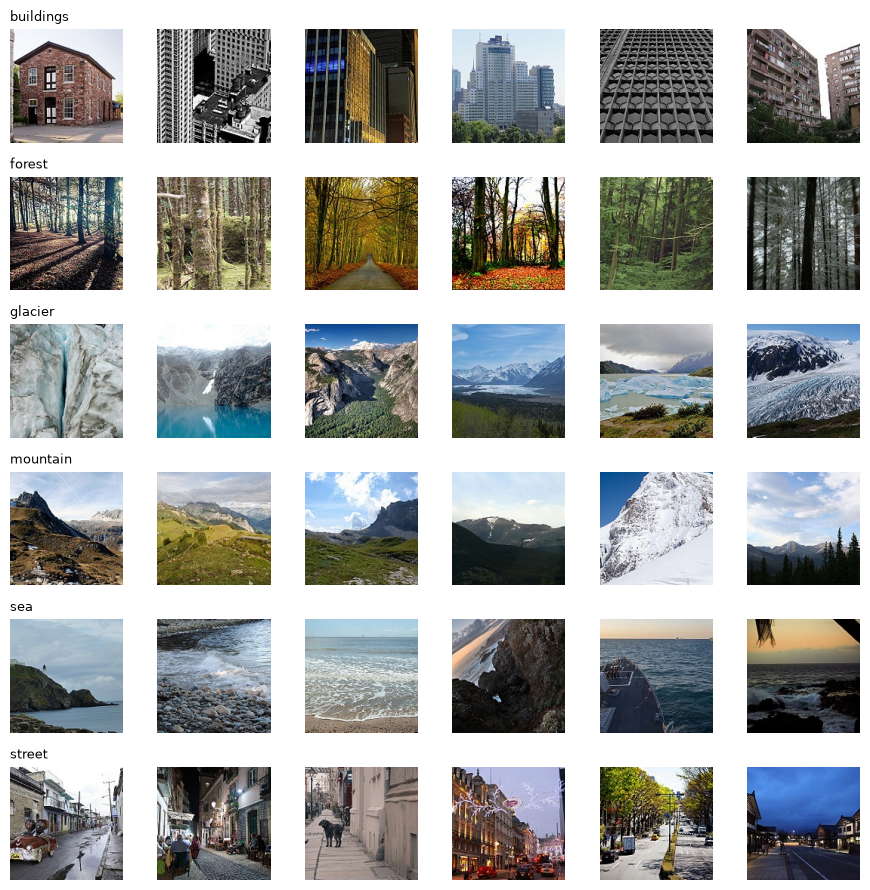

In [9]:
def _find_split(root, name, max_depth=4):
    root = Path(root)
    if not root.exists(): return None
    base_depth = len(root.parts)
    for dp, dns, _ in os.walk(root):
        if Path(dp).name == name and set(CLASSES) <= set(dns): return Path(dp)
        if len(Path(dp).parts) - base_depth >= max_depth: dns[:] = []
    return None

def locate_data():
    roots = [DATA_ROOT, os.environ.get("DATA_ROOT"), BASE / "data", "/kaggle/input", "./data"]
    for r in filter(None, roots):
        tr, te = _find_split(r, "seg_train"), _find_split(r, "seg_test")
        if tr and te: return tr, te
    for r in filter(None, roots):                      # zips
        r = Path(r)
        if (r / "seg_train.zip").exists() and (r / "seg_test.zip").exists():
            out = r / "_extraido"
            for z in ("seg_train.zip", "seg_test.zip"): zipfile.ZipFile(r / z).extractall(out)
            tr, te = _find_split(out, "seg_train"), _find_split(out, "seg_test")
            if tr and te: return tr, te
    raise FileNotFoundError(f"Não encontrei seg_train/seg_test. Verifica DATA_ROOT = {DATA_ROOT!r} "
                            "(a pasta deve conter seg_train e seg_test, cada uma com as 6 subpastas de classes).")

def list_folder(root, per_class=None):
    paths, labels = [], []
    for ci, c in enumerate(CLASSES):
        fs = sorted(f for f in (Path(root) / c).iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png"))
        if per_class: fs = fs[:per_class]
        paths += [str(f) for f in fs]; labels += [ci] * len(fs)
    return paths, np.array(labels)

def load_img(p):
    im = Image.open(p).convert("RGB")
    if im.size != (150, 150): im = im.resize((150, 150), Image.BILINEAR)
    return np.asarray(im)

def load_all(paths):
    with ThreadPoolExecutor(8) as ex: return np.stack(list(ex.map(load_img, paths)))    # uint8 (N,150,150,3)

TR_DIR, TE_DIR = locate_data(); print("treino:", TR_DIR, "\nteste: ", TE_DIR)
paths_tr, y_tr = list_folder(TR_DIR, 80 if SMOKE else None)
paths_te, y_te = list_folder(TE_DIR, 20 if SMOKE else None)
t0 = time.time(); X_tr, X_te = load_all(paths_tr), load_all(paths_te)
print(f"carregadas {len(X_tr)} imagens de treino e {len(X_te)} de teste em {time.time()-t0:.0f}s | {X_tr.nbytes/1e6:.0f} MB")

# ---- duplicados exatos / fuga de dados ----
md5 = lambda X: [hashlib.md5(X[i].tobytes()).hexdigest() for i in range(len(X))]
h_tr, h_te = md5(X_tr), set(md5(X_te)); keep, seen, n_leak, n_dup = [], set(), 0, 0
for i, h in enumerate(h_tr):
    if h in h_te: n_leak += 1; continue
    if h in seen: n_dup += 1; continue
    seen.add(h); keep.append(i)
DATA_STATS = dict(n_train_raw=len(X_tr), n_dup_in_train=n_dup, n_train_in_test=n_leak)
print(f"duplicados exatos no treino: {n_dup} | imagens do treino também presentes no teste: {n_leak}")
keep = np.array(keep); X_tr, y_tr, paths_tr = X_tr[keep], y_tr[keep], [paths_tr[i] for i in keep]
print(f"-> treino sem duplicados/fuga: {len(X_tr)} imagens")

# ---- hold-out fixo + subconjuntos aninhados estratificados (learning curve) ----
tr_pool, va_idx = train_test_split(np.arange(len(y_tr)), test_size=0.15, stratify=y_tr, random_state=SPLIT_SEED)
tr_pool = tr_pool[np.random.RandomState(SPLIT_SEED).permutation(len(tr_pool))]
def subset(idx, frac):
    if frac >= 1: return np.sort(idx)
    out = [idx[y_tr[idx] == c][:max(1, int(round((y_tr[idx] == c).sum() * frac)))] for c in range(N_CLS)]
    return np.sort(np.concatenate(out))
print("treino:", len(tr_pool), "| validação:", len(va_idx), "| teste:", len(X_te))
print("imagens por classe (treino):", {c: int(n) for c, n in zip(CLASSES, np.bincount(y_tr, minlength=N_CLS))})
print("baseline trivial (classe mais frequente) no teste:", round(float(np.bincount(y_te).max() / len(y_te)), 3), "| acaso:", round(1 / N_CLS, 3))

fig, axes = plt.subplots(N_CLS, 6, figsize=(9, 9)); rng = np.random.RandomState(0)
for ci, c in enumerate(CLASSES):
    for j, k in enumerate(rng.choice(np.where(y_tr == ci)[0], 6, replace=False)):
        axes[ci, j].imshow(X_tr[k]); axes[ci, j].axis("off")
    axes[ci, 0].set_title(c, loc="left", fontsize=9)
plt.tight_layout(); fig.savefig(FIG / "amostras.png", dpi=150); plt.show()

## 3 · Pipeline de dados
`tf.data` a partir dos arrays em memória. O *data augmentation* (que nos slides é feito com `ImageDataGenerator`: rotação, deslocamentos, zoom, flip) é feito aqui com as **camadas de pré-processamento do Keras**, só no treino:
* `none` — sem augmentation;
* `flip` — espelhamento horizontal;
* `full` — flip + rotação + zoom + translação + contraste (equivalente à configuração dos slides).

Cada modelo tem o seu pré-processamento: `x/255` nos modelos do zero; `preprocess_input` correspondente nos pré-treinados.

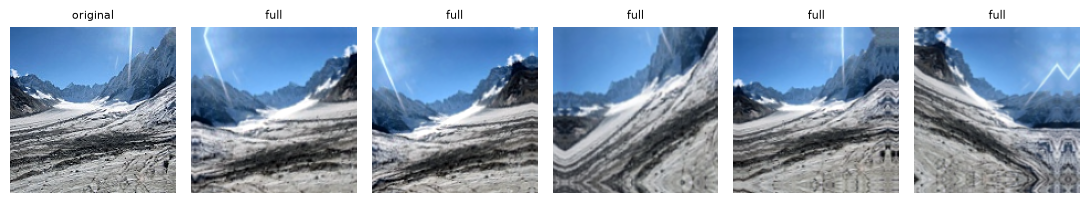

In [10]:
AUGS = {
    "none": None,
    "flip": keras.Sequential([layers.RandomFlip("horizontal")]),
    "full": keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.1), layers.RandomZoom(0.2),
                              layers.RandomTranslation(0.1, 0.1), layers.RandomContrast(0.2)]),
}
APPS = {   # nome: (construtor, preprocess_input, primeira camada a descongelar no fine-tuning = último bloco)
    "VGG16":          (keras.applications.VGG16,          keras.applications.vgg16.preprocess_input,               "block5_conv1"),
    "ResNet50":       (keras.applications.ResNet50,       keras.applications.resnet.preprocess_input,              "conv5_block1_1_conv"),
    "MobileNetV2":    (keras.applications.MobileNetV2,    keras.applications.mobilenet_v2.preprocess_input,        "block_13_expand"),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input,        "block6a_expand_conv"),
}
def prep_fn(arch): return (lambda x: x / 255.0) if arch in ("mlp", "cnn") else APPS[arch][1]

_TFCACHE = {}
def _as_tf(a):
    # um único tensor por array (sem cópias por experiência): os datasets só guardam índices e fazem gather
    k = id(a)
    if k not in _TFCACHE or _TFCACHE[k][0] is not a: _TFCACHE[k] = (a, tf.constant(a))
    return _TFCACHE[k][1]

def make_ds(X, y, idx, size, prep, aug="none", batch=64, shuffle=False, seed=0):
    Xt, yt = _as_tf(X), _as_tf(y)
    ds = tf.data.Dataset.from_tensor_slices(np.asarray(idx, dtype="int64"))
    if shuffle: ds = ds.shuffle(len(idx), seed=seed, reshuffle_each_iteration=True)
    ds = ds.batch(batch)
    def f(i):
        x = tf.cast(tf.gather(Xt, i), tf.float32)
        if size != X.shape[1]: x = tf.image.resize(x, (size, size))
        if aug != "none": x = AUGS[aug](x, training=True)
        return prep(x), tf.gather(yt, i)
    return ds.map(f, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

# exemplo de augmentation (para o relatório)
_x = X_tr[np.where(y_tr == 2)[0][0]].astype("float32")[None]
fig, ax = plt.subplots(1, 6, figsize=(11, 2)); ax[0].imshow(_x[0].astype("uint8")); ax[0].set_title("original", fontsize=8)
for k in range(1, 6): ax[k].imshow(np.clip(AUGS["full"](_x, training=True)[0].numpy(), 0, 255).astype("uint8")); ax[k].set_title("full", fontsize=8)
for a in ax: a.axis("off")
plt.tight_layout(); fig.savefig(FIG / "augmentation_exemplo.png", dpi=150); plt.show()

## 4 · Modelos
* **`mlp`** — baseline denso, como nos exemplos IMDB/Reuters: `Flatten → Dense(64) → Dense(64) → softmax`. Aprende padrões *globais*; não explora a estrutura espacial.
* **`cnn`** — convnet do slide *Building the network*: blocos `Conv2D(3×3, relu) + MaxPooling2D` com profundidade crescente, `Flatten`, `Dense` e `softmax`. Variantes de capacidade (`tiny`, `small`, `large`), `dropout` antes da `Dense` e regularização L2.
* **Pré-treinados (ImageNet):** `VGG16`, `ResNet50`, `MobileNetV2`, `EfficientNetB0` com cabeça nova (`GlobalAveragePooling2D → Dropout → Dense(6, softmax)`).
  * **`extract`** (*feature extraction*): base congelada, treina-se só a cabeça.
  * **`finetune`**: 1.ª fase igual a `extract`; 2.ª fase descongela o **último bloco** da base (as `BatchNormalization` ficam congeladas) e treina com *learning rate* muito baixo.

In [11]:
WIDTHS = {"tiny": ((16, 32, 64, 64), 64), "small": ((32, 64, 128, 128), 512), "large": ((64, 128, 256, 256), 512)}

def build_mlp(size):
    inp = keras.Input((size, size, 3)); x = layers.Flatten()(inp)
    x = layers.Dense(64, activation="relu")(x); x = layers.Dense(64, activation="relu")(x)
    return keras.Model(inp, layers.Dense(N_CLS, activation="softmax")(x), name="mlp")

def build_cnn(size, width, dropout, l2):
    convs, dense = WIDTHS[width]; reg = regularizers.l2(l2) if l2 > 0 else None
    inp = keras.Input((size, size, 3)); x = inp
    for i, f in enumerate(convs):
        x = layers.Conv2D(f, 3, activation="relu", kernel_regularizer=reg, name="last_conv" if i == len(convs) - 1 else f"conv{i+1}")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    if dropout > 0: x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense, activation="relu", kernel_regularizer=reg)(x)
    return keras.Model(inp, layers.Dense(N_CLS, activation="softmax")(x), name=f"cnn_{width}")

def build_pretrained(arch, size, dropout):
    base = APPS[arch][0](include_top=False, weights=WEIGHTS, input_shape=(size, size, 3), name="base"); base.trainable = False
    inp = keras.Input((size, size, 3)); x = base(inp, training=False)       # training=False: BatchNorm fica em modo de inferência
    x = layers.GlobalAveragePooling2D()(x)
    if dropout > 0: x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(N_CLS, activation="softmax")(x), name=arch.lower())

def set_finetune(model, arch):
    base = model.get_layer("base"); base.trainable = True; on = False
    for l in base.layers:
        on = on or l.name == APPS[arch][2]
        l.trainable = on and not isinstance(l, layers.BatchNormalization)

def build_from_spec(s):
    if s["arch"] == "mlp": return build_mlp(s["size"])
    if s["arch"] == "cnn": return build_cnn(s["size"], s["width"], s["dropout"], s["l2"])
    return build_pretrained(s["arch"], s["size"], s["dropout"])

for w in WIDTHS: print(f"cnn-{w}: {build_cnn(IMG_SIZE, w, 0, 0).count_params()/1e6:.2f} M parâmetros")
print(f"mlp: {build_mlp(IMG_SIZE).count_params()/1e6:.2f} M parâmetros")
build_cnn(IMG_SIZE, "small", 0.5, 0).summary()

cnn-tiny: 0.13 M parâmetros
cnn-small: 1.29 M parâmetros
cnn-large: 3.06 M parâmetros
mlp: 1.77 M parâmetros


Model: "cnn_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,998 (4.93 MB)

 Trainable params: 1,292,998 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

## 5 · Treino, avaliação e eficiência
`run_spec(spec)` treina uma experiência, restaura o melhor ponto **pela validação** (`EarlyStopping(restore_best_weights=True)`), avalia **uma vez** no teste e mede eficiência. GFLOPs são uma **estimativa analítica** (convoluções e camadas densas; 1 MAC = 2 FLOPs). A latência é a mediana de 1 imagem (CPU; e GPU se existir).

In [12]:
DEFAULT_SPEC = dict(arch="cnn", width="small", regime="scratch", aug="none", dropout=0.0, l2=0.0, frac=1.0, size=IMG_SIZE, seed=0, batch=64)

def resolve(spec):
    s = dict(DEFAULT_SPEC, **spec)
    if s["arch"] in ("mlp", "cnn"): s["regime"] = "scratch"
    elif s["regime"] == "scratch": raise ValueError("modelos pré-treinados: regime 'extract' ou 'finetune'")
    return s

def spec_name(s):
    n = f'{s["arch"]}' + (f'-{s["width"]}' if s["arch"] == "cnn" else "") + f'_{s["regime"]}_aug-{s["aug"]}_do{s["dropout"]}_l2-{s["l2"]}_f{s["frac"]}_r{s["size"]}_s{s["seed"]}'
    return n

def make_opt(lr): return keras.optimizers.Adam(lr) if OPTIMIZER == "adam" else keras.optimizers.RMSprop(lr)

def fit_phase(model, ds_tr, ds_va, epochs, lr):
    model.compile(optimizer=make_opt(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=P["patience"], restore_best_weights=True)]
    return model.fit(ds_tr, validation_data=ds_va, epochs=epochs, callbacks=cb, verbose=0, shuffle=False).history

def predict_probs(model, ds): return model.predict(ds, verbose=0).astype("float32")

def iter_layers(m):
    for l in m.layers:
        if isinstance(l, keras.Model): yield from iter_layers(l)
        else: yield l
def est_gflops(model):
    tot = 0
    for l in iter_layers(model):
        try:
            if isinstance(l, layers.DepthwiseConv2D):
                _, h, w, c = l.output.shape; k = l.kernel_size; tot += h * w * c * k[0] * k[1]
            elif isinstance(l, layers.Conv2D):
                _, h, w, co = l.output.shape; k = l.kernel_size; tot += h * w * co * k[0] * k[1] * l.input.shape[-1] // getattr(l, "groups", 1)
            elif isinstance(l, layers.Dense): tot += l.input.shape[-1] * l.units
        except Exception: pass
    return 2 * tot / 1e9
def latency_ms(model, size, device, runs=20):
    x = np.random.rand(1, size, size, 3).astype("float32")
    with tf.device(device):
        for _ in range(3): model(x, training=False).numpy()
        ts = []
        for _ in range(runs):
            t = time.perf_counter(); model(x, training=False).numpy(); ts.append(time.perf_counter() - t)
    return float(np.median(ts) * 1000)
def weights_mb(model):
    p = MODELS_DIR / "_tmp.weights.h5"; model.save_weights(p); mb = p.stat().st_size / 1e6; p.unlink(); return mb

def run_spec(spec, force=False, save_weights=False, return_model=False, write=True):
    s = resolve(spec); name = spec_name(s); out = RUNS / f"{name}.json"
    if out.exists() and not (force or FORCE) and not return_model:
        return json.load(open(out))
    keras.backend.clear_session(); keras.utils.set_random_seed(s["seed"])
    kind_pre = s["arch"] not in ("mlp", "cnn")
    tr_idx = subset(tr_pool, s["frac"]); prep = prep_fn(s["arch"])
    ds_tr = make_ds(X_tr, y_tr, tr_idx, s["size"], prep, s["aug"], s["batch"], True, s["seed"])
    ds_trc = make_ds(X_tr, y_tr, tr_idx, s["size"], prep)                    # treino "limpo" (sem augmentation)
    ds_va = make_ds(X_tr, y_tr, va_idx, s["size"], prep)
    ds_te = make_ds(X_te, y_te, np.arange(len(X_te)), s["size"], prep)
    model = build_from_spec(s); p_total = model.count_params(); t0 = time.time()
    if kind_pre:
        hist = fit_phase(model, ds_tr, ds_va, P["e_head"], 1e-3); boundary = len(hist["loss"])
        if s["regime"] == "finetune":
            set_finetune(model, s["arch"]); h2 = fit_phase(model, ds_tr, ds_va, P["e_ft"], 2e-5)
            hist = {k: hist[k] + h2[k] for k in hist}
    else:
        hist = fit_phase(model, ds_tr, ds_va, P["e_scratch"], 1e-3); boundary = None
    train_time = time.time() - t0
    va_acc_hist = np.array(hist["val_accuracy"]); best_epoch = int(va_acc_hist.argmax()) + 1

    pv, pt, ptr = predict_probs(model, ds_va), predict_probs(model, ds_te), predict_probs(model, ds_trc)
    ll = lambda p, y: float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-7, 1)).mean())
    yv, ytr_ = y_tr[va_idx], y_tr[tr_idx]
    pred = pt.argmax(1); rep = classification_report(y_te, pred, target_names=CLASSES, output_dict=True, zero_division=0)
    res = {**s, "name": name, "profile": PROFILE, "n_train": int(len(tr_idx)), "n_val": int(len(va_idx)), "n_test": int(len(X_te)), **DATA_STATS,
           "history": {k: [float(v) for v in vs] for k, vs in hist.items()}, "phase_boundary": boundary, "best_epoch": best_epoch,
           "epochs_run": len(hist["loss"]), "train_time_s": train_time,
           "train_clean_acc": float((ptr.argmax(1) == ytr_).mean()), "val_acc": float((pv.argmax(1) == yv).mean()), "val_loss": ll(pv, yv),
           "test_acc": float((pred == y_te).mean()), "test_loss": ll(pt, y_te), "test_f1_macro": float(f1_score(y_te, pred, average="macro")),
           "per_class_f1": {k: rep[k]["f1-score"] for k in CLASSES}, "confusion": confusion_matrix(y_te, pred, labels=range(N_CLS)).tolist(),
           "params_total": int(p_total), "params_trainable_final": int(sum(int(np.prod(w.shape)) for w in model.trainable_weights)),
           "size_mb": weights_mb(model), "gflops": est_gflops(model), "lat_cpu_ms": latency_ms(model, s["size"], "/CPU:0"),
           "lat_gpu_ms": latency_ms(model, s["size"], "/GPU:0") if GPUS else None,
           "device": "gpu" if GPUS else "cpu", "tf": tf.__version__, "date": datetime.datetime.now().isoformat(timespec="seconds")}
    if write:
        np.save(RUNS / f"{name}.test_probs.npy", pt.astype("float16")); json.dump(res, open(out, "w"), indent=1)
    if save_weights: model.save_weights(MODELS_DIR / f"{name}.weights.h5")
    print(f'{name}\n   -> val {res["val_acc"]:.4f} | test {res["test_acc"]:.4f} | F1 {res["test_f1_macro"]:.4f} | train(clean) {res["train_clean_acc"]:.4f} | '
          f'{p_total/1e6:.2f}M params | {res["gflops"]:.2f} GFLOPs | CPU {res["lat_cpu_ms"]:.0f} ms | {train_time/60:.1f} min')
    return (res, model) if return_model else res

def get_model(spec):
    # devolve o modelo treinado (usado no Grad-CAM). Recarrega os pesos se existirem; senão volta a treinar (sem alterar o .json).
    s = resolve(spec); w = MODELS_DIR / f"{spec_name(s)}.weights.h5"
    if w.exists(): m = build_from_spec(s); m.load_weights(w); return m
    return run_spec(s, return_model=True, save_weights=True, write=False)[1]

## 6 · Experiências
Cada grupo responde a uma pergunta; todas repetem-se para `N_SEEDS` *seeds*.

| Grupo | Pergunta |
|---|---|
| `baselines` | Um MLP denso chega? (referência) |
| `scratch` | Uma convnet simples (a do slide) já bate o MLP? Faz *overfitting*? |
| `regularization` | O que reduz o overfitting: *augmentation*, *dropout*, L2, ou menos/mais capacidade? |
| `pretrained` | *Feature extraction* vs *fine-tuning*, e custo (parâmetros/latência) de cada arquitetura |
| `learning_curve` | Quanto ajuda o pré-treino com poucos dados? |
| `augmentation` | Quanto vale o augmentation num modelo pré-treinado? |

In [13]:
SEEDS = range(P["n_seeds"]); REF = P["models"][0]           # REF = modelo de referência para learning curve e augmentation
def with_seeds(cfgs): return [{**c, "seed": s} for c in cfgs for s in SEEDS]
EXPERIMENTS = {
    "baselines": with_seeds([dict(arch="mlp")]),
    "scratch":   with_seeds([dict(arch="cnn", width="small")]),                                     # a CNN do slide, sem regularização
    "regularization": with_seeds([dict(arch="cnn", aug="flip"), dict(arch="cnn", aug="full"), dict(arch="cnn", dropout=0.5), dict(arch="cnn", l2=1e-3),
                                  dict(arch="cnn", aug="full", dropout=0.5), dict(arch="cnn", aug="full", dropout=0.5, l2=1e-3),
                                  dict(arch="cnn", width="tiny"), dict(arch="cnn", width="large")]),
    "pretrained": with_seeds([dict(arch=m, regime=r, aug="flip", dropout=0.3) for m in P["models"] for r in ("extract", "finetune")]),
    "learning_curve": with_seeds([{**c, "frac": f} for f in P["fracs"] for c in (dict(arch="cnn", aug="full", dropout=0.5),
                                  dict(arch=REF, regime="extract", aug="flip", dropout=0.3), dict(arch=REF, regime="finetune", aug="flip", dropout=0.3))]),
    "augmentation": with_seeds([dict(arch=REF, regime="finetune", aug=a, dropout=0.3) for a in ("none", "flip", "full")]),
}
todo = [(g, s) for g in RUN_GROUPS for s in EXPERIMENTS[g]]
uniq = {spec_name(resolve(s)): s for _, s in todo}
pend = [n for n in uniq if FORCE or not (RUNS / f"{n}.json").exists()]
print(f"{len(uniq)} experiências distintas nos grupos {RUN_GROUPS} | {len(uniq) - len(pend)} já feitas | {len(pend)} por correr")

17 experiências distintas nos grupos ['baselines', 'scratch', 'regularization', 'pretrained', 'learning_curve', 'augmentation'] | 0 já feitas | 17 por correr


In [14]:
# ============================ EXECUTAR ============================
t_all = time.time(); done = 0
for g in RUN_GROUPS:
    print(f"\n######## grupo: {g}")
    for s in EXPERIMENTS[g]:
        n = spec_name(resolve(s)); was = (RUNS / f"{n}.json").exists() and not FORCE
        run_spec(s); done += (not was)
print(f"\nconcluído: {done} experiências novas em {(time.time()-t_all)/60:.1f} min")


######## grupo: baselines

mlp_scratch_aug-none_do0.0_l2-0.0_f1.0_r96_s0
   -> val 0.5635 | test 0.5517 | F1 0.5438 | train(clean) 0.5900 | 1.77M params | 0.00 GFLOPs | CPU 6 ms | 0.2 min

######## grupo: scratch
cnn-small_scratch_aug-none_do0.0_l2-0.0_f1.0_r96_s0
   -> val 0.8174 | test 0.8107 | F1 0.8123 | train(clean) 0.8443 | 1.29M params | 0.17 GFLOPs | CPU 28 ms | 5.1 min

######## grupo: regularization
cnn-small_scratch_aug-flip_do0.0_l2-0.0_f1.0_r96_s0
   -> val 0.8226 | test 0.8260 | F1 0.8270 | train(clean) 0.8503 | 1.29M params | 0.17 GFLOPs | CPU 14 ms | 10.4 min
cnn-small_scratch_aug-full_do0.0_l2-0.0_f1.0_r96_s0
   -> val 0.7570 | test 0.7610 | F1 0.7593 | train(clean) 0.7559 | 1.29M params | 0.17 GFLOPs | CPU 14 ms | 4.6 min
cnn-small_scratch_aug-none_do0.5_l2-0.0_f1.0_r96_s0
   -> val 0.8226 | test 0.8297 | F1 0.8292 | train(clean) 0.8549 | 1.29M params | 0.17 GFLOPs | CPU 33 ms | 115.4 min
cnn-small_scratch_aug-none_do0.0_l2-0.001_f1.0_r96_s0
   -> val 0.8088 | test 0

# Análise dos resultados
A partir daqui só se usam os `.json` guardados. Convenções dos gráficos: **cor = família de modelo** (fixa), **marcador = regime** (círculo = do zero, quadrado = *extract*, triângulo = *finetune*); barras de erro = desvio-padrão entre *seeds*. O "melhor modelo" é escolhido pela **validação**.

In [15]:
ENT_ORDER = ["mlp", "cnn", "VGG16", "ResNet50", "MobileNetV2", "EfficientNetB0"]
COLOR = {m: PALETTE[i] for i, m in enumerate(ENT_ORDER)}; MARK = {"scratch": "o", "extract": "s", "finetune": "^"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e6e3"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": .8, "axes.edgecolor": "#bdbdb8", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "font.size": 9, "axes.axisbelow": True})
from matplotlib.ticker import FuncFormatter, NullFormatter, MaxNLocator
from matplotlib.lines import Line2D
savefig = lambda fig, n: fig.savefig(FIG / f"{n}.png", dpi=200, bbox_inches="tight")

df = pd.DataFrame([json.load(open(f)) for f in sorted(RUNS.glob("*.json"))])
assert len(df), f"Sem resultados em {RUNS}. Corre primeiro a secção 6."
def label_of(r):
    if r.arch == "mlp": return "MLP"
    if r.arch == "cnn":
        v = [f"aug={r.aug}"] + ([f"do={r.dropout}"] if r.dropout else []) + ([f"L2={r.l2:g}"] if r.l2 else [])
        return f"CNN-{r.width} ({', '.join(v)})"
    return f"{r.arch} ({'extract' if r.regime == 'extract' else 'ft'})" + (f" aug={r.aug}" if r.aug != "flip" else "")
df["label"] = df.apply(label_of, axis=1)
df.drop(columns=["history", "per_class_f1", "confusion"]).to_csv(RESULTS / f"results_{PROFILE}.csv", index=False)
KEYS = ["arch", "width", "regime", "aug", "dropout", "l2", "frac", "size"]
MET = ["test_acc", "test_f1_macro", "val_acc", "train_clean_acc", "params_total", "size_mb", "gflops", "lat_cpu_ms", "lat_gpu_ms", "train_time_s", "best_epoch"]
g = df.groupby(KEYS, dropna=False)
S = pd.concat([g[MET].mean().add_suffix("_mean"), g[["test_acc", "val_acc", "test_f1_macro"]].std(ddof=1).fillna(0).add_suffix("_std"), g.size().rename("n_seeds")], axis=1).reset_index()
S["label"] = S.apply(label_of, axis=1); S["gap_train_val"] = S.train_clean_acc_mean - S.val_acc_mean; S["gap_val_test"] = S.val_acc_mean - S.test_acc_mean
FULL = S[(S.frac == 1.0) & (S["size"] == IMG_SIZE)].copy()          # 100 % dos dados
pm = lambda m, s: [f"{a:.3f} ± {b:.3f}" for a, b in zip(m, s)]
print(f"{len(df)} experiências carregadas ({PROFILE}) | seeds por configuração: {sorted(S.n_seeds.unique())}")

T = FULL.sort_values("val_acc_mean", ascending=False)
T1 = pd.DataFrame({"modelo": T.label, "seeds": T.n_seeds, "val acc": pm(T.val_acc_mean, T.val_acc_std), "test acc": pm(T.test_acc_mean, T.test_acc_std),
                   "F1 macro": pm(T.test_f1_macro_mean, T.test_f1_macro_std), "gap treino−val": T.gap_train_val.round(3), "params (M)": (T.params_total_mean / 1e6).round(2),
                   "GFLOPs": T.gflops_mean.round(2), "CPU ms": T.lat_cpu_ms_mean.round(1), "treino (min)": (T.train_time_s_mean / 60).round(1)})
T1.to_csv(RESULTS / f"tabela_principal_{PROFILE}.csv", index=False); display(T1.reset_index(drop=True))

17 experiências carregadas (rapido) | seeds por configuração: [np.int64(1)]


,modelo,seeds,val acc,test acc,F1 macro,gap treino−val,params (M),GFLOPs,CPU ms,treino (min)
0,MobileNetV2 (ft) aug=none,1,0.924 ± 0.000,0.923 ± 0.000,0.924 ± 0.000,0.046,2.27,0.11,192.5,4.5
1,MobileNetV2 (ft),1,0.923 ± 0.000,0.926 ± 0.000,0.928 ± 0.000,0.042,2.27,0.11,179.7,4.5
2,MobileNetV2 (extract),1,0.910 ± 0.000,0.915 ± 0.000,0.917 ± 0.000,0.024,2.27,0.11,279.6,1.9
3,MobileNetV2 (ft) aug=full,1,0.907 ± 0.000,0.903 ± 0.000,0.905 ± 0.000,0.007,2.27,0.11,239.3,6.1
4,CNN-large (aug=none),1,0.831 ± 0.000,0.829 ± 0.000,0.830 ± 0.000,0.049,3.06,0.64,25.6,14.8
5,CNN-small (aug=flip),1,0.823 ± 0.000,0.826 ± 0.000,0.827 ± 0.000,0.028,1.29,0.17,14.2,10.4
6,"CNN-small (aug=none, do=0.5)",1,0.823 ± 0.000,0.830 ± 0.000,0.829 ± 0.000,0.032,1.29,0.17,32.6,115.4
7,CNN-small (aug=none),1,0.817 ± 0.000,0.811 ± 0.000,0.812 ± 0.000,0.027,1.29,0.17,28.0,5.1
8,"CNN-small (aug=none, L2=0.001)",1,0.809 ± 0.000,0.807 ± 0.000,0.805 ± 0.000,0.022,1.29,0.17,18.6,5.7
9,"CNN-small (aug=full, do=0.5)",1,0.786 ± 0.000,0.776 ± 0.000,0.773 ± 0.000,-0.017,1.29,0.17,26.3,5.8


## 7 · Overfitting: baseline vs modelo regularizado
Curvas de *loss* e *accuracy* (primeira *seed*). Esperado (slide *Comments*): sem regularização o treino sobe para perto de 100 % enquanto a validação estagna e a *validation loss* volta a subir.

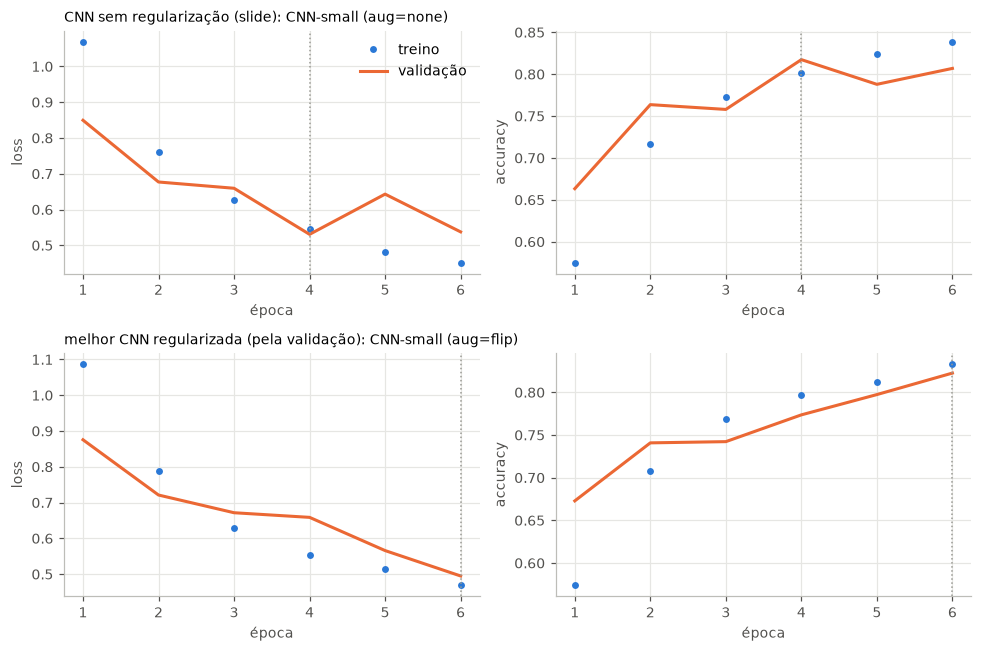

In [16]:
def hist_of(name): return json.load(open(RUNS / f"{name}.json"))
def plot_hist(axs, name, title):
    r = hist_of(name); h = r["history"]; ep = np.arange(1, len(h["loss"]) + 1)
    for ax, (a, b, yl) in zip(axs, [("loss", "val_loss", "loss"), ("accuracy", "val_accuracy", "accuracy")]):
        ax.plot(ep, h[a], "o", color=PALETTE[0], ms=3.5, label="treino"); ax.plot(ep, h[b], "-", color=PALETTE[1], lw=2, label="validação")
        ax.axvline(r["best_epoch"], color="#9a9a94", ls=":", lw=1)
        if r["phase_boundary"]: ax.axvline(r["phase_boundary"] + .5, color="#9a9a94", ls="--", lw=1)
        ax.set_xlabel("época"); ax.set_ylabel(yl); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    axs[0].set_title(title, fontsize=9, loc="left")

def seed0(label_): 
    d = df[(df.label == label_)].sort_values("seed"); return d.iloc[0]["name"] if len(d) else None
base_lbl = "CNN-small (aug=none)"
reg_cands = FULL[(FULL.arch == "cnn") & (FULL.width == "small")].sort_values("val_acc_mean", ascending=False)
best_cnn_lbl = reg_cands.iloc[0].label if len(reg_cands) else None
pairs = [(l, t) for l, t in [(base_lbl, "CNN sem regularização (slide)"), (best_cnn_lbl, "melhor CNN regularizada (pela validação)")] if l and seed0(l)]
if pairs:
    fig, axes = plt.subplots(len(pairs), 2, figsize=(9, 3 * len(pairs)), squeeze=False)
    for (l, t), axs in zip(pairs, axes): plot_hist(axs, seed0(l), f"{t}: {l}")
    axes[0, 0].legend(frameon=False); fig.tight_layout(); savefig(fig, "overfitting_cnn"); plt.show()
else: print("Corre os grupos 'scratch' e 'regularization'.")

## 8 · O que reduz o overfitting? (ablation de regularização)
Variantes da CNN `small` com 100 % dos dados. Seleção pela validação; o teste mostra a generalização. O *gap* "treino−validação" mede a memorização.

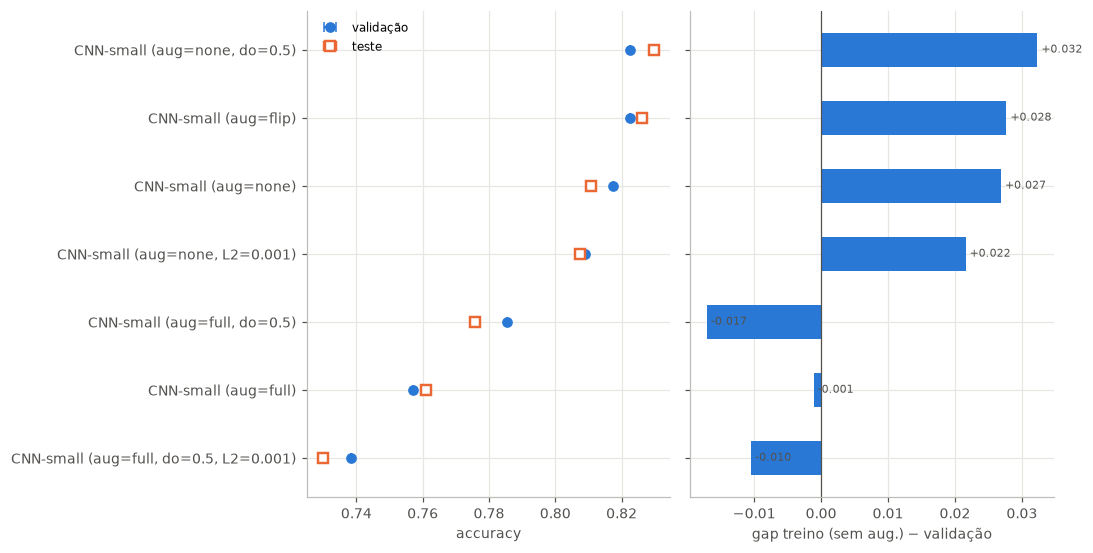

,variante,seeds,val acc,test acc,gap treino−val
0,"CNN-small (aug=none, do=0.5)",1,0.823 ± 0.000,0.830 ± 0.000,0.032
1,CNN-small (aug=flip),1,0.823 ± 0.000,0.826 ± 0.000,0.028
2,CNN-small (aug=none),1,0.817 ± 0.000,0.811 ± 0.000,0.027
3,"CNN-small (aug=none, L2=0.001)",1,0.809 ± 0.000,0.807 ± 0.000,0.022
4,"CNN-small (aug=full, do=0.5)",1,0.786 ± 0.000,0.776 ± 0.000,-0.017
5,CNN-small (aug=full),1,0.757 ± 0.000,0.761 ± 0.000,-0.001
6,"CNN-small (aug=full, do=0.5, L2=0.001)",1,0.738 ± 0.000,0.730 ± 0.000,-0.010


In [17]:
R = FULL[(FULL.arch == "cnn") & (FULL.width == "small")].sort_values("val_acc_mean")
if len(R) > 1:
    fig, axes = plt.subplots(1, 2, figsize=(10, 0.5 * len(R) + 1.6), sharey=True)
    axes[0].errorbar(R.val_acc_mean, R.label, xerr=R.val_acc_std, fmt="o", color=PALETTE[0], capsize=3, label="validação")
    axes[0].errorbar(R.test_acc_mean, R.label, xerr=R.test_acc_std, fmt="s", color=PALETTE[1], mfc="white", mew=1.6, capsize=3, label="teste")
    axes[0].set_xlabel("accuracy"); axes[0].legend(frameon=False, fontsize=8)
    axes[1].barh(R.label, R.gap_train_val, color=PALETTE[0], height=.5); axes[1].axvline(0, color=INK2, lw=.8); axes[1].set_xlabel("gap treino (sem aug.) − validação")
    for y_, v in enumerate(R.gap_train_val): axes[1].text(v, y_, f" {v:+.3f}", va="center", fontsize=7, color=INK2)
    fig.tight_layout(); savefig(fig, "regularizacao"); plt.show()
    display(pd.DataFrame({"variante": R.label, "seeds": R.n_seeds, "val acc": pm(R.val_acc_mean, R.val_acc_std), "test acc": pm(R.test_acc_mean, R.test_acc_std),
                          "gap treino−val": R.gap_train_val.round(3)}).iloc[::-1].reset_index(drop=True))
else: print("Corre o grupo 'regularization'.")

## 9 · Capacidade do modelo
Slide *Reducing the network's size*: mais parâmetros = mais capacidade de memorização. Variantes `tiny`/`small`/`large` **sem** regularização.

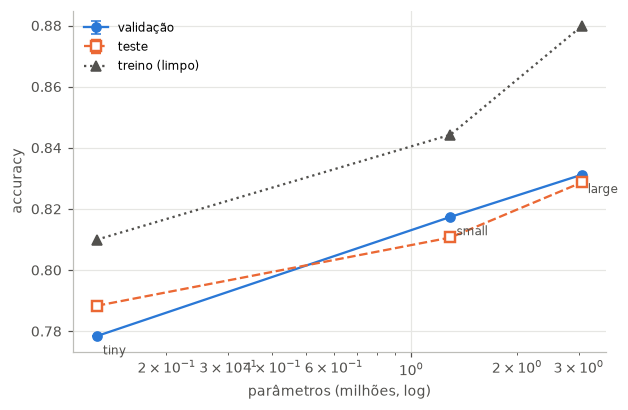

In [18]:
C = FULL[(FULL.arch == "cnn") & (FULL.aug == "none") & (FULL.dropout == 0) & (FULL.l2 == 0)].sort_values("params_total_mean")
if len(C) > 1:
    fig, ax = plt.subplots(figsize=(5.8, 3.8)); x = C.params_total_mean / 1e6
    ax.errorbar(x, C.val_acc_mean, yerr=C.val_acc_std, fmt="o-", color=PALETTE[0], capsize=3, label="validação")
    ax.errorbar(x, C.test_acc_mean, yerr=C.test_acc_std, fmt="s--", color=PALETTE[1], mfc="white", mew=1.6, capsize=3, label="teste")
    ax.errorbar(x, C.train_clean_acc_mean, fmt="^:", color=INK2, ms=6, label="treino (limpo)")
    for xi, w in zip(x, C.width): ax.annotate(w, (xi, C.loc[C.width == w, "val_acc_mean"].iloc[0]), xytext=(4, -12), textcoords="offset points", fontsize=8, color=INK2)
    ax.set_xscale("log"); ax.set_xlabel("parâmetros (milhões, log)"); ax.set_ylabel("accuracy"); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); savefig(fig, "capacidade"); plt.show()
else: print("Corre o grupo 'regularization' (variantes tiny/large).")

## 10 · Pré-treinados: accuracy vs custo
*Feature extraction* vs *fine-tuning* em cada arquitetura, comparados com o MLP e a CNN. A linha tracejada é a **fronteira de Pareto** (nenhum modelo é simultaneamente mais pequeno/rápido e mais exato). Quem fica abaixo da fronteira é dominado.

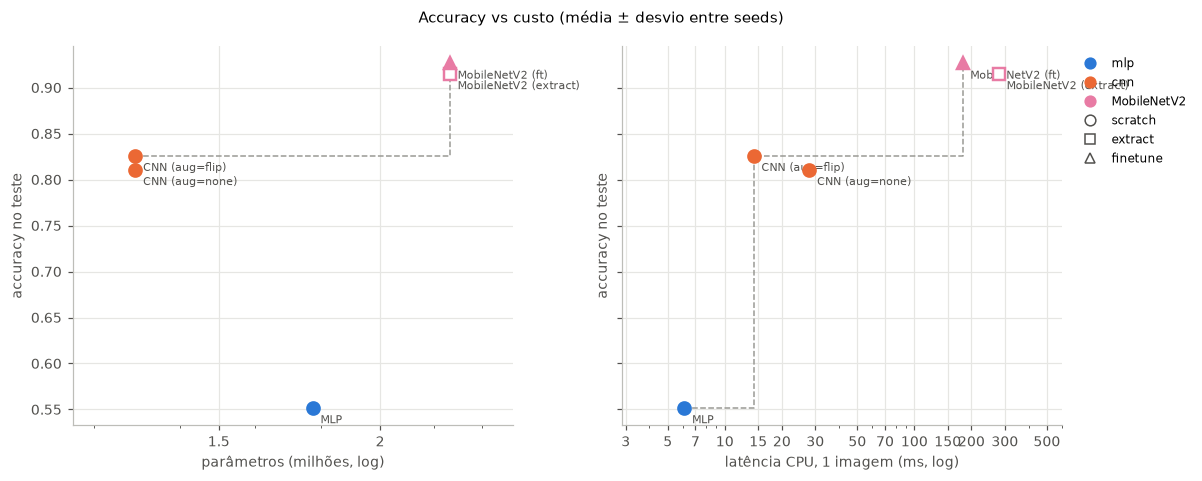

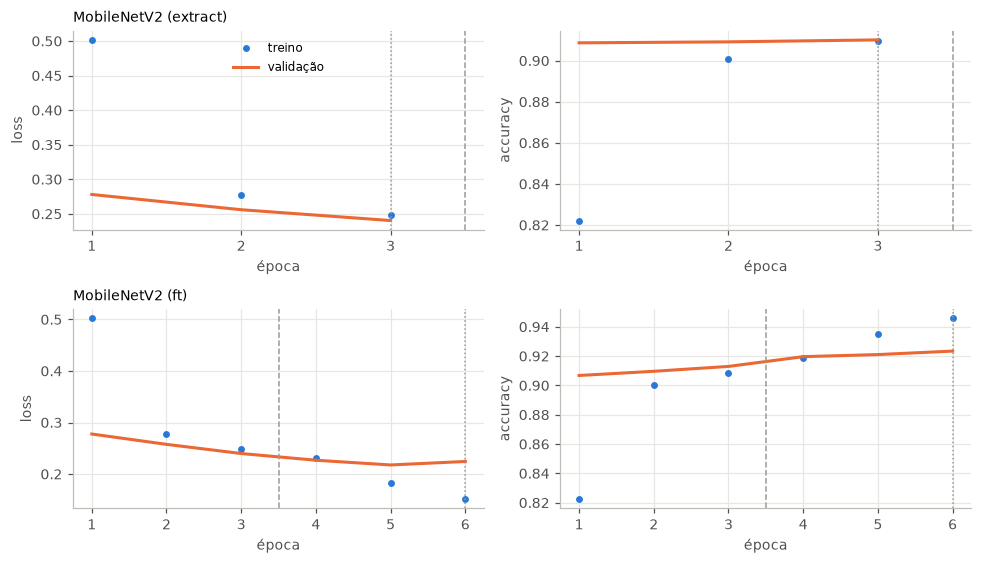

In [19]:
def ent(r): return r.arch
P1 = FULL.copy()
keep_cnn = [l for l in [base_lbl, best_cnn_lbl] if l]
P1 = P1[(P1.arch != "cnn") | P1.label.isin(keep_cnn)]
P1 = P1[(P1.arch.isin(["mlp", "cnn"])) | (P1.aug == "flip")]
def pareto(x, y):
    best, front = -1, []
    for xi, yi in sorted(zip(x, y), key=lambda t: (t[0], -t[1])):
        if yi > best: front.append((xi, yi)); best = yi
    return front
def scat(ax, d, xcol, xlabel):
    d = d.dropna(subset=[xcol])
    for _, r in d.iterrows():
        ax.errorbar(r[xcol], r.test_acc_mean, yerr=r.test_acc_std, fmt=MARK[r.regime], color=COLOR[r.arch], ms=8, mfc=COLOR[r.arch] if r.regime != "extract" else "white",
                    mew=1.6, capsize=2, lw=1, zorder=3)
        ax.annotate(r.label.replace("CNN-small ", "CNN "), (r[xcol], r.test_acc_mean), xytext=(5, -10), textcoords="offset points", fontsize=7, color=INK2)
    f = pareto(d[xcol], d.test_acc_mean)
    if len(f) > 1: ax.step(*zip(*f), where="post", color="#9a9a94", ls="--", lw=1, zorder=1)
    ax.set_xscale("log"); ax.margins(x=.2); lo, hi = ax.get_xlim()
    ax.set_xticks([t for t in [.1, .2, .3, .5, .7, 1, 1.5, 2, 3, 5, 7, 10, 15, 20, 30, 50, 70, 100, 150, 200, 300, 500] if lo <= t <= hi])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xlabel(xlabel); ax.set_ylabel("accuracy no teste")
if len(P1):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
    scat(axes[0], P1.assign(pm_=P1.params_total_mean / 1e6), "pm_", "parâmetros (milhões, log)"); scat(axes[1], P1, "lat_cpu_ms_mean", "latência CPU, 1 imagem (ms, log)")
    h = [Line2D([], [], marker="o", ls="", color=COLOR[m], label=m, ms=7) for m in ENT_ORDER if m in P1.arch.values]
    h += [Line2D([], [], marker=MARK[r], ls="", color=INK2, mfc="none", label=r, ms=7) for r in MARK if r in P1.regime.values]
    axes[1].legend(handles=h, frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle("Accuracy vs custo (média ± desvio entre seeds)", fontsize=10); fig.tight_layout(); savefig(fig, "pareto"); plt.show()

# curvas de treino dos pré-treinados (linha tracejada = início do fine-tuning)
PT = df[(df.arch.isin(APPS)) & (df.frac == 1.0) & (df.aug == "flip") & (df.seed == df.seed.min())].sort_values(["arch", "regime"])
if len(PT):
    fig, axes = plt.subplots(len(PT), 2, figsize=(9, 2.6 * len(PT)), squeeze=False)
    for (_, r), axs in zip(PT.iterrows(), axes): plot_hist(axs, r["name"], r["label"])
    axes[0, 0].legend(frameon=False, fontsize=8); fig.tight_layout(); savefig(fig, "curvas_pretreinados"); plt.show()

## 11 · Learning curve: quanto ajuda o pré-treino com poucos dados?

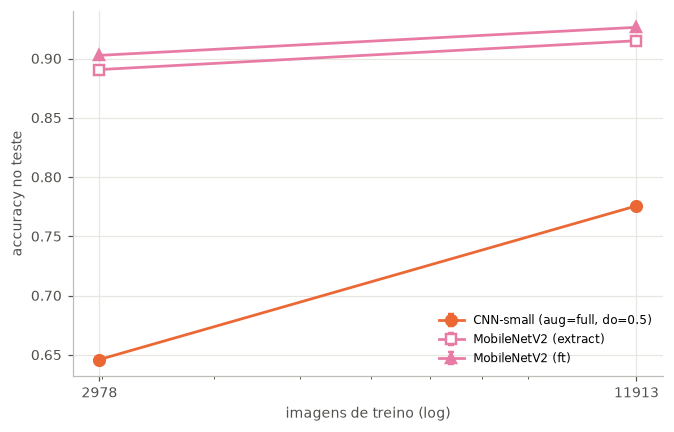

frac,0.25,1.00
label,,
"CNN-small (aug=full, do=0.5)",0.646,0.776
MobileNetV2 (extract),0.891,0.915
MobileNetV2 (ft),0.903,0.926


In [20]:
LC = S[(S["size"] == IMG_SIZE) & S.apply(lambda r: (r.arch == "cnn" and r.aug == "full" and r.dropout == 0.5 and r.l2 == 0 and r.width == "small") or
                                               (r.arch in APPS and r.aug == "flip"), axis=1)]
LC = LC[LC.groupby("label").frac.transform("nunique") > 1]
if len(LC):
    ntr = df.groupby("frac").n_train.first()
    fig, ax = plt.subplots(figsize=(6.2, 4))
    for lbl, d in LC.groupby("label"):
        d = d.sort_values("frac"); r0 = d.iloc[0]
        ax.errorbar([ntr[f] for f in d.frac], d.test_acc_mean, yerr=d.test_acc_std, color=COLOR[r0.arch], marker=MARK[r0.regime], ms=7, lw=1.8, capsize=2,
                    mfc=COLOR[r0.arch] if r0.regime != "extract" else "white", mew=1.6, label=lbl)
    xs = sorted(ntr[f] for f in LC.frac.unique()); ax.set_xscale("log"); ax.set_xticks(xs)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v)}")); ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("imagens de treino (log)"); ax.set_ylabel("accuracy no teste"); ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); savefig(fig, "learning_curve"); plt.show()
    display(LC.pivot_table(index="label", columns="frac", values="test_acc_mean").round(3))
else: print("Corre o grupo 'learning_curve'.")

## 12 · Data augmentation num modelo pré-treinado

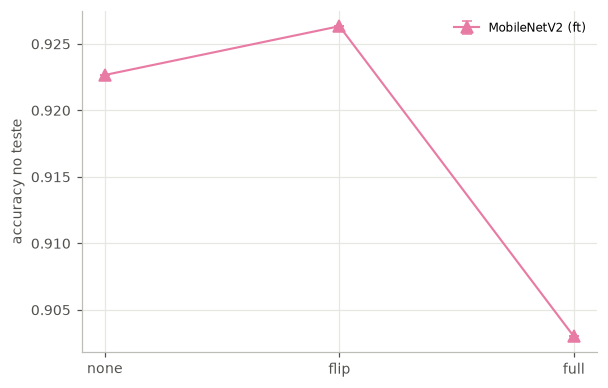

gap_train_val               test_acc_mean         \
aug                                flip   full   none          flip   full   
label                                                                        
MobileNetV2 (ft)                  0.042    NaN    NaN         0.926    NaN   
MobileNetV2 (ft) aug=full           NaN  0.007    NaN           NaN  0.903   
MobileNetV2 (ft) aug=none           NaN    NaN  0.046           NaN    NaN   

                                  
aug                         none  
label                             
MobileNetV2 (ft)             NaN  
MobileNetV2 (ft) aug=full    NaN  
MobileNetV2 (ft) aug=none  0.923

In [21]:
A = S[(S["size"] == IMG_SIZE) & (S.frac == 1.0) & (S.arch.isin(APPS)) & (S.regime == "finetune")]
A = A[A.groupby("arch").aug.transform("nunique") > 1]
if len(A):
    order = ["none", "flip", "full"]; fig, ax = plt.subplots(figsize=(5.6, 3.6))
    for k, (m, d) in enumerate(A.groupby("arch")):
        d = d.set_index("aug").reindex([a for a in order if a in d.aug.values])
        ax.errorbar([order.index(a) + k * .05 for a in d.index], d.test_acc_mean, yerr=d.test_acc_std, color=COLOR[m], marker="^", ms=8, lw=1.4, capsize=3, label=f"{m} (ft)")
    ax.set_xticks(range(3)); ax.set_xticklabels(order); ax.set_ylabel("accuracy no teste"); ax.legend(frameon=False, fontsize=8); fig.tight_layout(); savefig(fig, "augmentation_pretreinado"); plt.show()
    display(A.pivot_table(index="label", columns="aug", values=["test_acc_mean", "gap_train_val"]).round(3))
else: print("Corre o grupo 'augmentation'.")

## 13 · Análise de erros
Matrizes de confusão (normalizadas por linha, somadas entre *seeds*) do **melhor modelo** e do **melhor modelo do zero** (ambos escolhidos pela validação), F1 por classe e as imagens mal classificadas com maior confiança.

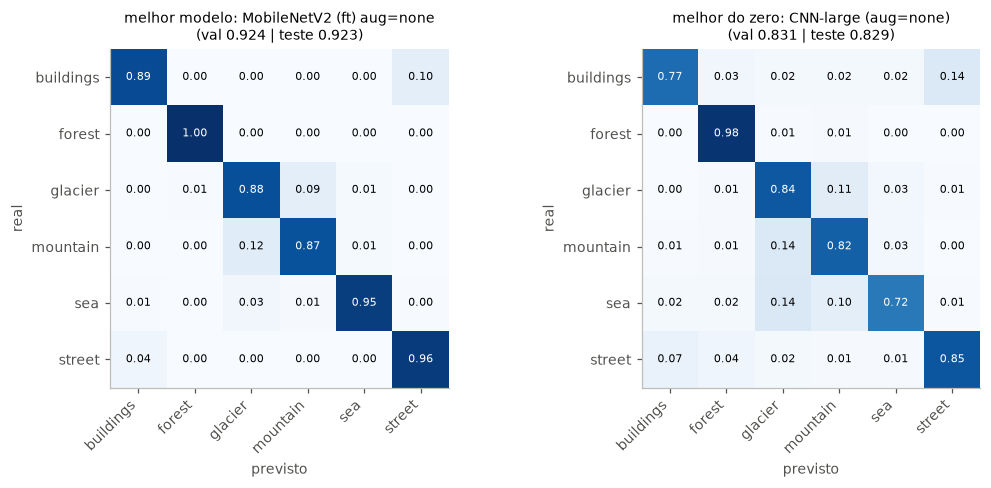

,buildings,forest,glacier,mountain,sea,street
modelo,,,,,,
MobileNetV2 (ft) aug=none,0.917,0.994,0.871,0.877,0.956,0.931
MobileNetV2 (ft),0.917,0.993,0.879,0.883,0.962,0.933
MobileNetV2 (extract),0.922,0.990,0.851,0.861,0.952,0.927
MobileNetV2 (ft) aug=full,0.903,0.986,0.845,0.840,0.937,0.916
CNN-large (aug=none),0.818,0.934,0.787,0.789,0.795,0.857
CNN-small (aug=flip),0.800,0.944,0.775,0.783,0.811,0.849
"CNN-small (aug=none, do=0.5)",0.784,0.948,0.799,0.775,0.823,0.847
CNN-small (aug=none),0.790,0.945,0.756,0.767,0.780,0.836
"CNN-small (aug=none, L2=0.001)",0.714,0.934,0.781,0.786,0.792,0.821


Confusões mais frequentes (real -> previsto) no melhor modelo: [('mountain', 'glacier', 61), ('glacier', 'mountain', 52), ('buildings', 'street', 44), ('street', 'buildings', 20), ('sea', 'glacier', 17)]


In [22]:
def agg_cm(d): return np.sum([np.array(c) for c in d.confusion], axis=0)
def plot_cm(ax, cm, title):
    n = cm / cm.sum(1, keepdims=True); ax.imshow(n, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    ax.set_xticks(range(N_CLS)); ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticks(range(N_CLS)); ax.set_yticklabels(CLASSES)
    for i in range(N_CLS):
        for j in range(N_CLS): ax.text(j, i, f"{n[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if n[i, j] > .5 else "black")
    ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.set_title(title, fontsize=9)

def rows_of(r): return df[(df.arch == r.arch) & (df.width == r.width) & (df.regime == r.regime) & (df.aug == r.aug) & (df.dropout == r.dropout) &
                          (df.l2 == r.l2) & (df.frac == r.frac) & (df["size"] == r["size"])].sort_values("seed")
FS = FULL.sort_values("val_acc_mean", ascending=False)
best = FS.iloc[0]; scr = FS[FS.regime == "scratch"]; best_scratch = scr.iloc[0] if len(scr) else None
picks = [("melhor modelo", best)] + ([("melhor do zero", best_scratch)] if best_scratch is not None and best_scratch.label != best.label else [])
fig, axes = plt.subplots(1, len(picks), figsize=(4.9 * len(picks), 4.5), squeeze=False)
for ax, (t, r) in zip(axes[0], picks): plot_cm(ax, agg_cm(rows_of(r)), f"{t}: {r.label}\n(val {r.val_acc_mean:.3f} | teste {r.test_acc_mean:.3f})")
fig.tight_layout(); savefig(fig, "confusao"); plt.show()

f1 = pd.DataFrame([{"modelo": r.label, **pd.DataFrame(list(rows_of(r).per_class_f1)).mean().to_dict()} for _, r in FS.iterrows()]).set_index("modelo")
display(f1.round(3))
cm = agg_cm(rows_of(best)).astype(float); np.fill_diagonal(cm, 0)
top = sorted([(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(N_CLS) for j in range(N_CLS)], reverse=True)[:5]
print("Confusões mais frequentes (real -> previsto) no melhor modelo:", [(a, b, int(n)) for n, a, b in top])

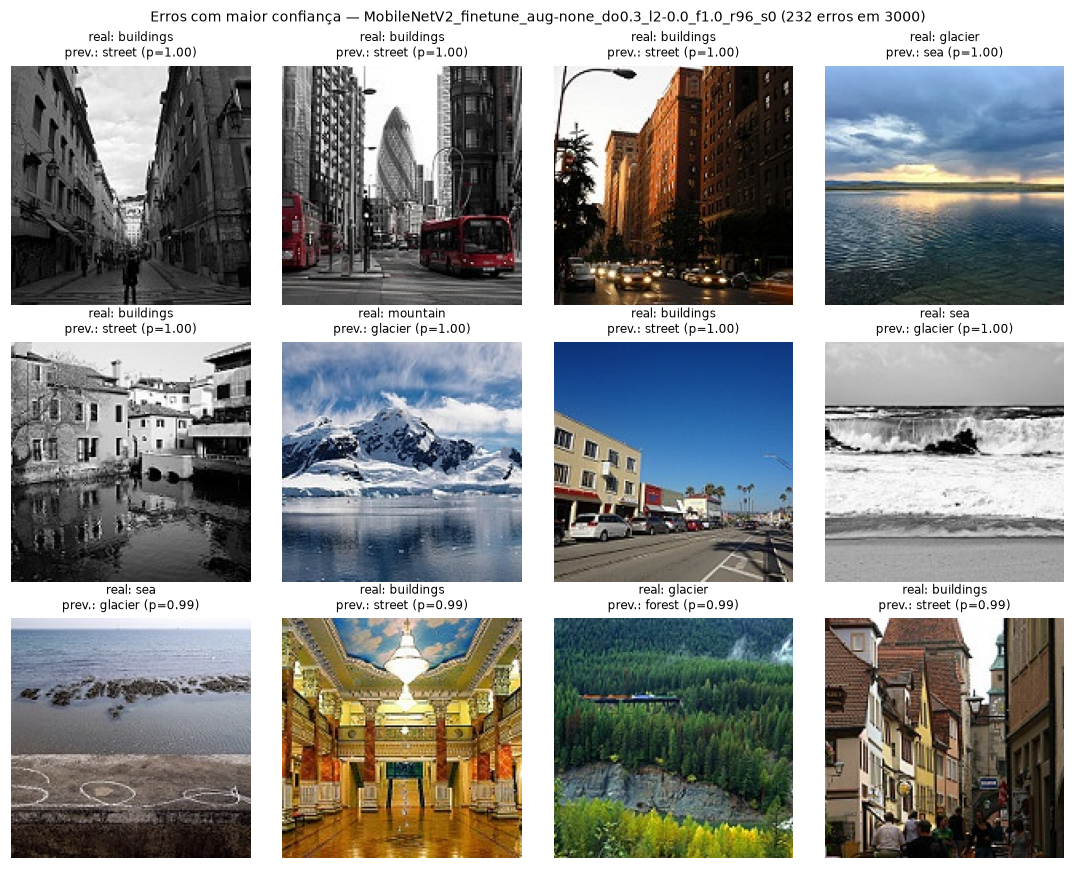

In [23]:
# imagens mal classificadas com maior confiança (melhor modelo, primeira seed)
r0 = rows_of(best).iloc[0]; probs = np.load(RUNS / f"{r0['name']}.test_probs.npy").astype("float32")
pred, conf = probs.argmax(1), probs.max(1); wrong = np.where(pred != y_te)[0]; wrong = wrong[np.argsort(-conf[wrong])][:12]
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, k in zip(axes.ravel(), wrong):
    ax.imshow(X_te[k]); ax.axis("off"); ax.set_title(f"real: {CLASSES[y_te[k]]}\nprev.: {CLASSES[pred[k]]} (p={conf[k]:.2f})", fontsize=8)
for ax in axes.ravel()[len(wrong):]: ax.axis("off")
fig.suptitle(f"Erros com maior confiança — {r0['name']} ({(pred != y_te).sum()} erros em {len(y_te)})", fontsize=9); fig.tight_layout(); savefig(fig, "erros"); plt.show()

### Grad-CAM (material opcional da aula)
Mapa de ativação de classe: que zonas da imagem levaram o modelo à classe prevista. Útil para perceber **porque** erra (ex.: usa o céu em vez da montanha?). Se os pesos do melhor modelo não estiverem guardados, este passo volta a treiná-lo uma vez (sem alterar os resultados já registados).

MobileNetV2_finetune_aug-none_do0.3_l2-0.0_f1.0_r96_s0
   -> val 0.9244 | test 0.9227 | F1 0.9243 | train(clean) 0.9707 | 2.27M params | 0.11 GFLOPs | CPU 219 ms | 5.9 min


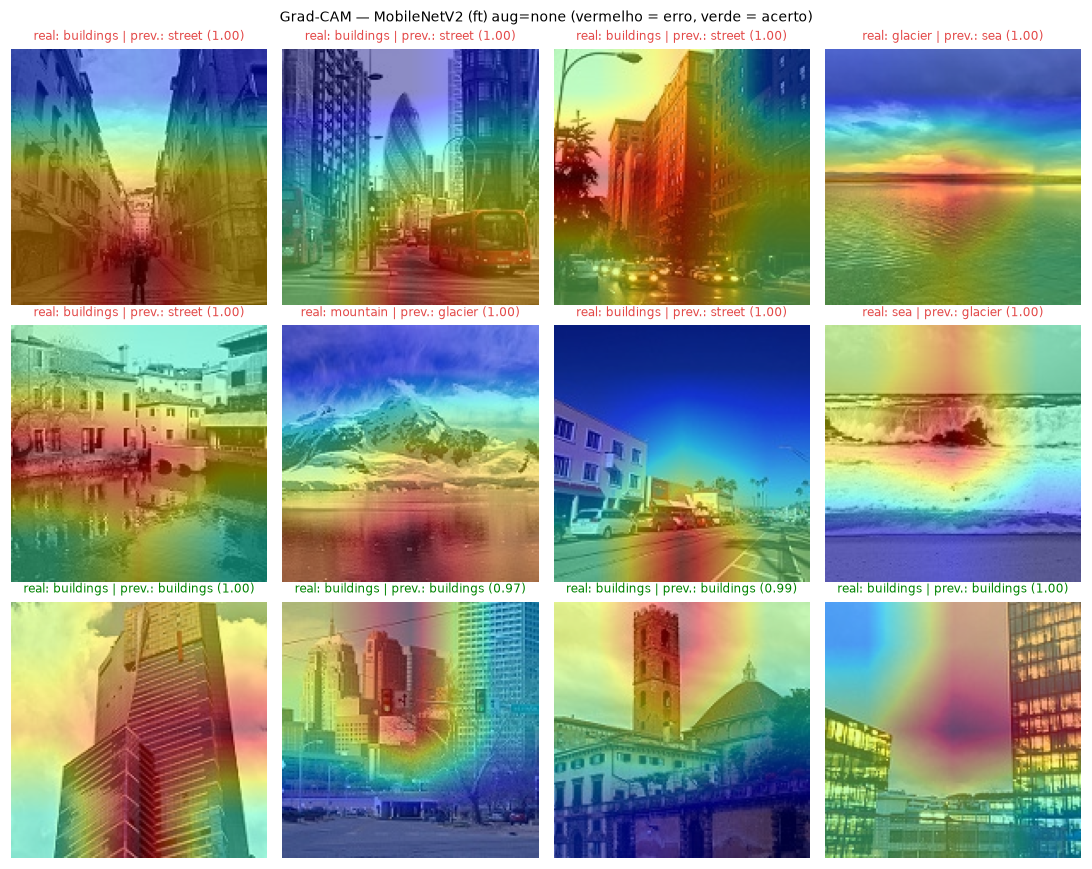

In [24]:
def gradcam_fn(model, arch):
    feat_name = "base" if arch in APPS else ("last_conv" if arch == "cnn" else None)
    if feat_name is None: return None
    feat_model = model.get_layer("base") if arch in APPS else keras.Model(model.inputs, model.get_layer(feat_name).output)
    idx = [l.name for l in model.layers].index(feat_name); head = model.layers[idx + 1:]
    def run(x, cls=None):
        f = feat_model(x, training=False)
        with tf.GradientTape() as tape:
            tape.watch(f); h = f
            for l in head: h = l(h)
            c = tf.argmax(h[0]) if cls is None else cls; score = h[0, c]
        gr = tape.gradient(score, f); w = tf.reduce_mean(gr, axis=(1, 2), keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(w * f, axis=-1))[0].numpy(); cam = cam / (cam.max() + 1e-8)
        return cam, int(c), h.numpy()[0]
    return run

spec_best = {k: best[k] for k in ["arch", "width", "regime", "aug", "dropout", "l2", "frac", "size"]}; spec_best["seed"] = int(r0["seed"])
gm = get_model(spec_best); cam_fn = gradcam_fn(gm, best.arch)
if cam_fn is not None:
    prep = prep_fn(best.arch); size = int(best["size"])
    def cam_overlay(k):
        x = X_te[k].astype("float32")[None]; x = tf.image.resize(x, (size, size)) if size != x.shape[1] else tf.constant(x)
        cam, c, p = cam_fn(prep(x)); up = tf.image.resize(cam[None, :, :, None], (150, 150)).numpy()[0, :, :, 0]
        heat = plt.cm.jet(up)[..., :3]; return np.clip(0.55 * X_te[k] / 255.0 + 0.45 * heat, 0, 1), c, p.max()
    ok = np.where(pred == y_te)[0][:4]; ks = list(wrong[:8]) + list(ok)
    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    for ax, k in zip(axes.ravel(), ks):
        im, c, p = cam_overlay(k); ax.imshow(im); ax.axis("off")
        ax.set_title(f"real: {CLASSES[y_te[k]]} | prev.: {CLASSES[c]} ({p:.2f})", fontsize=8, color="#e34948" if c != y_te[k] else "#008300")
    fig.suptitle(f"Grad-CAM — {best.label} (vermelho = erro, verde = acerto)", fontsize=9); fig.tight_layout(); savefig(fig, "gradcam"); plt.show()

## 14 · Comparação com soluções existentes no Kaggle
O enunciado pede comparação com soluções existentes quando se usa um dataset do Kaggle. Preencher com 2–3 notebooks públicos do dataset (nome, link, arquitetura, accuracy reportada). **Não inventar valores** — usar só o que vem reportado nesses notebooks.

In [25]:
KAGGLE_REF = [
    # ("Nome do notebook", "https://www.kaggle.com/...", "arquitetura", 0.000),
]
rows_cmp = [{"fonte": n, "modelo": m, "test acc": a, "link": u} for n, u, m, a in KAGGLE_REF]
rows_cmp += [{"fonte": "este trabalho", "modelo": r.label, "test acc": round(r.test_acc_mean, 4), "link": ""} for _, r in FS.head(3).iterrows()]
cmp_df = pd.DataFrame(rows_cmp); display(cmp_df); cmp_df.to_csv(RESULTS / f"comparacao_kaggle_{PROFILE}.csv", index=False)
print("Figuras:", sorted(p.name for p in FIG.glob("*.png")))

,fonte,modelo,test acc,link
0,este trabalho,MobileNetV2 (ft) aug=none,0.9227,
1,este trabalho,MobileNetV2 (ft),0.9263,
2,este trabalho,MobileNetV2 (extract),0.9150,


Figuras: ['amostras.png', 'augmentation_exemplo.png', 'augmentation_pretreinado.png', 'capacidade.png', 'confusao.png', 'curvas_pretreinados.png', 'erros.png', 'gradcam.png', 'learning_curve.png', 'overfitting_cnn.png', 'pareto.png', 'regularizacao.png']


## 15 · Conclusões (preencher com os resultados reais)
Rascunho de perguntas a responder no relatório com base nas tabelas e figuras acima:

1. **Baseline vs CNN:** quanto melhora a CNN face ao MLP, e porquê (padrões locais, invariância à translação)?
2. **Overfitting:** em que época começa na CNN sem regularização? Qual o *gap* treino−validação?
3. **Regularização:** qual das técnicas (augmentation, dropout, L2) reduz mais o *gap*, e qual melhora mais a *accuracy* de validação? Combinam bem?
4. **Capacidade:** o modelo `large` ganha algo sobre o `small` ou só memoriza mais?
5. **Pré-treino:** *extract* vs *finetune* — o ganho do *fine-tuning* compensa o custo? Qual a arquitetura na fronteira de Pareto?
6. **Dados:** a partir de que quantidade de imagens a CNN do zero se aproxima do modelo pré-treinado?
7. **Erros:** que pares de classes se confundem e porquê (Grad-CAM)? Há imagens ambíguas ou mal etiquetadas?
8. **Mensagem final:** uma frase do tipo "a partir de X parâmetros o ganho é marginal".